# Campo de fase de un motor de corriente directa

**Objetivo:** localizar el punto de operación bajo voltaje constante.
Sin par de carga, con corriente $i_a$ y velocidad $\omega$:

$$\dot i_a=\frac{V_a-R_a i_a-K_e\omega}{L_a},\qquad
\dot\omega=\frac{K_t i_a-B\omega}{J}.$$

Aplicamos $V_a=12$ V y los parámetros del motor del ejemplo original.
El punto de equilibrio no es el origen porque existe una entrada constante.

Equilibrio (A, rad/s): [  1.57894737 126.31578947]
Autovalores: [-20.85595724+0.j  -3.64404276+0.j]


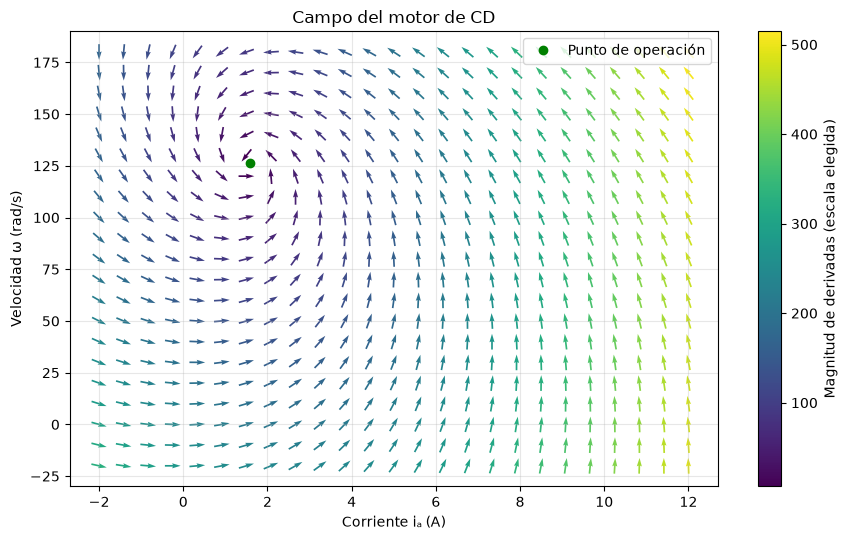

In [1]:
%matplotlib inline
import numpy as np
from sistemas_dinamicos import campo_fase

Va, Ra, La, Kt, Ke, J, B = 12.0, 1.2, 0.05, 0.08, 0.08, 0.002, 0.001
A = np.array([[-Ra/La, -Ke/La], [Kt/J, -B/J]])
entrada = np.array([Va/La, 0])
equilibrio = np.linalg.solve(A, -entrada)
print("Equilibrio (A, rad/s):", equilibrio)
print("Autovalores:", np.linalg.eigvals(A))
fig, ax = campo_fase(lambda i, w: ((Va-Ra*i-Ke*w)/La, (Kt*i-B*w)/J),
                     (-2, 12), (-20, 180), titulo="Campo del motor de CD",
                     xlabel="Corriente iₐ (A)", ylabel="Velocidad ω (rad/s)")
ax.plot(*equilibrio, "go", label="Punto de operación")
ax.legend();

## Interpretación y práctica

El equilibrio es aproximadamente $1.58$ A y $126.32$ rad/s. Los autovalores
tienen parte real negativa; por tratarse de un sistema afín estable con entrada
constante, las trayectorias convergen al punto de operación. La magnitud de
las flechas combina derivadas de unidades distintas; no es una rapidez física.

**Practica:** reduce $V_a$ a 6 V. ¿Qué cambia en el equilibrio y qué permanece
igual en los autovalores?